In [3]:
import numpy as np

from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [4]:
faces = fetch_olivetti_faces()

X = faces.images
y = faces.target

print("Images shape:", X.shape)
print("Labels shape:", y.shape)
print("Number of identities:", len(np.unique(y)))
print("Images per identity:", np.bincount(y))

Images shape: (400, 64, 64)
Labels shape: (400,)
Number of identities: 40
Images per identity: [10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10
 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10]


In [5]:
seed = 26001
rng = np.random.default_rng(seed)

print("Random seed:", seed)

Random seed: 26001


In [6]:
train_idx = []
val_idx = []
test_idx = []

for person in range(40):

    person_idx = np.where(y == person)[0]

    person_idx = rng.permutation(person_idx)

    train_idx.extend(person_idx[:6])

    val_idx.extend(person_idx[6:8])

    test_idx.extend(person_idx[8:10])


train_idx = np.array(train_idx)
val_idx = np.array(val_idx)
test_idx = np.array(test_idx)


print("Training images:", len(train_idx))
print("Validation images:", len(val_idx))
print("Test images:", len(test_idx))

Training images: 240
Validation images: 80
Test images: 80


In [7]:
np.savez(
    "olivetti_split.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)


In [8]:
X_flat = X.reshape(400, 4096)

print("Flattened images shape:", X_flat.shape)

Flattened images shape: (400, 4096)


In [9]:
X_train = X_flat[train_idx]
y_train = y[train_idx]

X_val = X_flat[val_idx]
y_val = y[val_idx]

X_test = X_flat[test_idx]
y_test = y[test_idx]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (240, 4096)
X_val: (80, 4096)
X_test: (80, 4096)


Question Number 1(A)

In [10]:
depth_values = [2, 4, 8, 16, None]
leaf_values = [1, 2, 4]

results = []

best_model = None
best_val_accuracy = -1
best_depth = None
best_leaf = None

for depth in depth_values:
    for leaf in leaf_values:

        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=seed
        )

        model.fit(X_train, y_train)

        val_predictions = model.predict(X_val)
        val_accuracy = accuracy_score(y_val, val_predictions)

        results.append({
            "max_depth": depth,
            "min_samples_leaf": leaf,
            "val_accuracy": val_accuracy
        })

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_model = model
            best_depth = depth
            best_leaf = leaf


print("All 15 model settings:")

for result in results:
    print(result)

print("\nSelected depth:", best_depth)
print("Selected min_samples_leaf:", best_leaf)
print("Best validation accuracy:", best_val_accuracy)

All 15 model settings:
{'max_depth': 2, 'min_samples_leaf': 1, 'val_accuracy': 0.0625}
{'max_depth': 2, 'min_samples_leaf': 2, 'val_accuracy': 0.0625}
{'max_depth': 2, 'min_samples_leaf': 4, 'val_accuracy': 0.0625}
{'max_depth': 4, 'min_samples_leaf': 1, 'val_accuracy': 0.0875}
{'max_depth': 4, 'min_samples_leaf': 2, 'val_accuracy': 0.0875}
{'max_depth': 4, 'min_samples_leaf': 4, 'val_accuracy': 0.0875}
{'max_depth': 8, 'min_samples_leaf': 1, 'val_accuracy': 0.175}
{'max_depth': 8, 'min_samples_leaf': 2, 'val_accuracy': 0.175}
{'max_depth': 8, 'min_samples_leaf': 4, 'val_accuracy': 0.175}
{'max_depth': 16, 'min_samples_leaf': 1, 'val_accuracy': 0.325}
{'max_depth': 16, 'min_samples_leaf': 2, 'val_accuracy': 0.325}
{'max_depth': 16, 'min_samples_leaf': 4, 'val_accuracy': 0.325}
{'max_depth': None, 'min_samples_leaf': 1, 'val_accuracy': 0.6}
{'max_depth': None, 'min_samples_leaf': 2, 'val_accuracy': 0.575}
{'max_depth': None, 'min_samples_leaf': 4, 'val_accuracy': 0.6}

Selected depth: N

In [11]:
train_predictions = best_model.predict(X_train)
train_accuracy = accuracy_score(y_train, train_predictions)

val_predictions = best_model.predict(X_val)
val_accuracy = accuracy_score(y_val, val_predictions)

test_predictions = best_model.predict(X_test)
test_accuracy = accuracy_score(y_test, test_predictions)


leaf_ids = best_model.apply(X_train)

unique_leaves, leaf_counts = np.unique(
    leaf_ids,
    return_counts=True
)

number_of_leaves = best_model.get_n_leaves()
mean_samples_per_leaf = np.mean(leaf_counts)
fraction_single_sample_leaves = np.mean(leaf_counts == 1)


print("Selected max_depth:", best_depth)
print("Selected min_samples_leaf:", best_leaf)

print("Train accuracy:", train_accuracy)
print("Validation accuracy:", val_accuracy)
print("Clean test accuracy:", test_accuracy)

print("Number of leaves:", number_of_leaves)
print("Mean samples per leaf:", mean_samples_per_leaf)
print(
    "Fraction of leaves with one training example:",
    fraction_single_sample_leaves
)

Selected max_depth: None
Selected min_samples_leaf: 1
Train accuracy: 1.0
Validation accuracy: 0.6
Clean test accuracy: 0.5125
Number of leaves: 44
Mean samples per leaf: 5.454545454545454
Fraction of leaves with one training example: 0.09090909090909091


Question No. 1(B)

In [ ]:

B_values = [1, 5, 10, 25, 50, 100, 200]
n_train = len(X_train)

bagging_rng = np.random.default_rng(seed)

frozen_depth = best_depth
frozen_leaf = best_leaf

train_predictions_all = []
val_predictions_all = []
test_predictions_all = []

distinct_counts = []
oob_masks = []

for i in range(200):

    sample_idx = bagging_rng.choice(
        n_train, size=n_train, replace=True
    )

    oob_mask = np.ones(n_train, dtype=bool)
    oob_mask[np.unique(sample_idx)] = False
    oob_masks.append(oob_mask)

    distinct_counts.append(len(np.unique(sample_idx)))

    tree = DecisionTreeClassifier(
        max_depth=frozen_depth,
        min_samples_leaf=frozen_leaf,
        random_state=seed + i
    )

    tree.fit(X_train[sample_idx], y_train[sample_idx])

    train_predictions_all.append(tree.predict(X_train))
    val_predictions_all.append(tree.predict(X_val))
    test_predictions_all.append(tree.predict(X_test))


train_predictions_all = np.array(train_predictions_all)
val_predictions_all = np.array(val_predictions_all)
test_predictions_all = np.array(test_predictions_all)
oob_masks = np.array(oob_masks)

print("Trees trained:", len(train_predictions_all))


Trees trained: 200
Prediction arrays saved for Q1(c).


Question number 1(C)

In [ ]:

import matplotlib.pyplot as plt
from itertools import combinations

oob_accuracies = []
disagreements = []
mean_margins = []

for B in B_values:

    oob_votes = np.zeros((n_train, 40), dtype=int)
    oob_vote_counts = np.zeros(n_train, dtype=int)

    for i in range(B):

        mask = oob_masks[i]

        predictions = train_predictions_all[i]

        for j in np.where(mask)[0]:
            oob_votes[j, predictions[j]] += 1
            oob_vote_counts[j] += 1

    has_oob_votes = oob_vote_counts > 0

    oob_final_predictions = np.argmax(
        oob_votes[has_oob_votes], axis=1
    )

    oob_accuracy = accuracy_score(
        y_train[has_oob_votes],
        oob_final_predictions
    )

    oob_accuracies.append(oob_accuracy)

    pair_disagreements = []

    for i, j in combinations(range(B), 2):
        disagreement = np.mean(
            val_predictions_all[i] != val_predictions_all[j]
        )
        pair_disagreements.append(disagreement)

    if B == 1:
        avg_disagreement = 0.0
    else:
        avg_disagreement = np.mean(pair_disagreements)

    disagreements.append(avg_disagreement)

    votes = np.zeros((len(y_val), 40), dtype=int)

    for i in range(B):
        for image_no, prediction in enumerate(
            val_predictions_all[i]
        ):
            votes[image_no, prediction] += 1

    vote_fractions = votes / B

    sorted_votes = np.sort(vote_fractions, axis=1)

    winning_fraction = sorted_votes[:, -1]
    runner_up_fraction = sorted_votes[:, -2]

    margins = winning_fraction - runner_up_fraction
    mean_margin = np.mean(margins)

    mean_margins.append(mean_margin)


print("B | OOB accuracy | Disagreement | Mean vote margin")

for i, B in enumerate(B_values):
    print(
        f"{B:3d} | "
        f"{oob_accuracies[i]:.4f} | "
        f"{disagreements[i]:.4f} | "
        f"{mean_margins[i]:.4f}"
    )

B | OOB accuracy | Disagreement | Mean vote margin
  1 | 0.2963 | 0.0000 | 1.0000
  5 | 0.3779 | 0.7975 | 0.2450
 10 | 0.4619 | 0.7700 | 0.2800
 25 | 0.6042 | 0.7734 | 0.2825
 50 | 0.7042 | 0.7773 | 0.2850
100 | 0.7250 | 0.7811 | 0.2880
200 | 0.7875 | 0.7844 | 0.2855


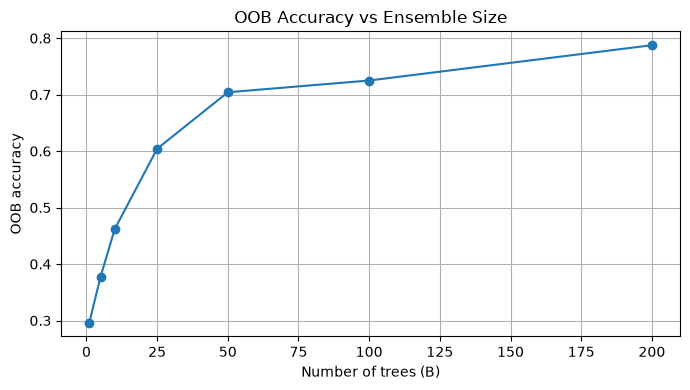

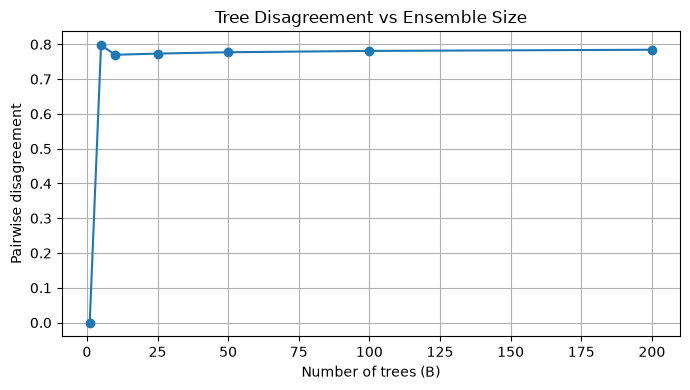

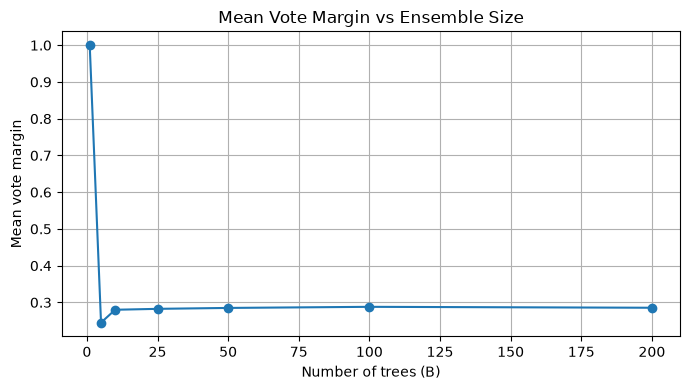

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(B_values, oob_accuracies, marker="o")
plt.xlabel("Number of trees (B)")
plt.ylabel("OOB accuracy")
plt.title("OOB Accuracy vs Ensemble Size")
plt.grid(True)
plt.tight_layout()
plt.savefig("oob_accuracy.png", dpi=300)
plt.show()


plt.figure(figsize=(7, 4))
plt.plot(B_values, disagreements, marker="o")
plt.xlabel("Number of trees (B)")
plt.ylabel("Pairwise disagreement")
plt.title("Tree Disagreement vs Ensemble Size")
plt.grid(True)
plt.tight_layout()
plt.savefig("tree_disagreement.png", dpi=300)
plt.show()


plt.figure(figsize=(7, 4))
plt.plot(B_values, mean_margins, marker="o")
plt.xlabel("Number of trees (B)")
plt.ylabel("Mean vote margin")
plt.title("Mean Vote Margin vs Ensemble Size")
plt.grid(True)
plt.tight_layout()
plt.savefig("mean_vote_margin.png", dpi=300)
plt.show()

Question Number 1(D)

In [ ]:


X_masked_test = X_test.reshape(-1, 64, 64).copy()
X_masked_test[:, 24:40, 24:40] = 0
X_masked_test = X_masked_test.reshape(-1, 4096)

B_final = 100
n_train = len(X_train)

bagging_rng = np.random.default_rng(seed)
final_trees = []

for i in range(B_final):
    sample_idx = bagging_rng.choice(
        n_train, size=n_train, replace=True
    )

    tree = DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_leaf=best_leaf,
        random_state=seed + i
    )

    tree.fit(X_train[sample_idx], y_train[sample_idx])
    final_trees.append(tree)


def evaluate_models(X_eval, y_true, set_name):
    # Single tree
    tree_pred = best_model.predict(X_eval)
    tree_prob = best_model.predict_proba(X_eval).max(axis=1)

    # Bagging: collect each tree's prediction
    all_preds = np.array([
        tree.predict(X_eval) for tree in final_trees
    ])

    bag_pred = []
    bag_conf = []
    vote_counts = []

    for j in range(len(X_eval)):
        counts = np.bincount(all_preds[:, j], minlength=40)
        bag_pred.append(np.argmax(counts))
        bag_conf.append(np.max(counts) / B_final)
        vote_counts.append(counts)

    bag_pred = np.array(bag_pred)
    bag_conf = np.array(bag_conf)

    print("\n", set_name)
    print("Single Tree accuracy:",
          accuracy_score(y_true, tree_pred))
    print("Single Tree mean confidence:",
          np.mean(tree_prob))
    print("Bagging accuracy:",
          accuracy_score(y_true, bag_pred))
    print("Bagging mean confidence:",
          np.mean(bag_conf))

    return tree_pred, bag_pred, vote_counts


# Evaluate clean and masked test sets
tree_clean, bag_clean, clean_votes = evaluate_models(
    X_test, y_test, "CLEAN TEST SET"
)

tree_masked, bag_masked, masked_votes = evaluate_models(
    X_masked_test, y_test, "MASKED TEST SET"
)


# Find two faces corrected by bagging
# and two faces where both models are wrong
corrected = []
both_wrong = []

for i in range(len(y_test)):
    tree_correct = tree_clean[i] == y_test[i]
    bag_correct = bag_clean[i] == y_test[i]

    if not tree_correct and bag_correct:
        corrected.append(i)

    if not tree_correct and not bag_correct:
        both_wrong.append(i)


def show_cases(indices, title):
    print("\n", title)

    for i in indices[:2]:
        counts = clean_votes[i]
        top_classes = np.argsort(counts)[::-1][:5]

        print("\nTest face index:", i)
        print("True identity:", y_test[i])
        print("Single Tree prediction:", tree_clean[i])
        print("Bagging prediction:", bag_clean[i])
        print("Bagging vote counts (top classes):")

        for class_id in top_classes:
            if counts[class_id] > 0:
                print("Identity", class_id,
                      ":", counts[class_id], "votes")


show_cases(corrected, "BAGGING CORRECTS THE TREE")
show_cases(both_wrong, "BOTH MODELS ARE WRONG")

print("\nNumber of corrected faces:", len(corrected))
print("Number of faces where both are wrong:", len(both_wrong))



 CLEAN TEST SET
Single Tree accuracy: 0.5125
Single Tree mean confidence: 1.0
Bagging accuracy: 0.85
Bagging mean confidence: 0.38525

 MASKED TEST SET
Single Tree accuracy: 0.3375
Single Tree mean confidence: 1.0
Bagging accuracy: 0.725
Bagging mean confidence: 0.269

 BAGGING CORRECTS THE TREE

Test face index: 0
True identity: 0
Single Tree prediction: 9
Bagging prediction: 0
Bagging vote counts (top classes):
Identity 0 : 34 votes
Identity 7 : 20 votes
Identity 15 : 9 votes
Identity 9 : 9 votes
Identity 3 : 3 votes

Test face index: 1
True identity: 0
Single Tree prediction: 12
Bagging prediction: 0
Bagging vote counts (top classes):
Identity 0 : 32 votes
Identity 16 : 18 votes
Identity 11 : 5 votes
Identity 3 : 4 votes
Identity 15 : 4 votes

 BOTH MODELS ARE WRONG

Test face index: 6
True identity: 3
Single Tree prediction: 15
Bagging prediction: 9
Bagging vote counts (top classes):
Identity 9 : 8 votes
Identity 17 : 8 votes
Identity 1 : 7 votes
Identity 39 : 6 votes
Identity 26 

In [ ]:

# Print the four face examples clearly

def print_face_examples(indices, title):
    print("\n" + title)

    for i in indices[:2]:
        counts = clean_votes[i]
        top_classes = np.argsort(counts)[::-1][:5]

        print("\nTest face index:", i)
        print("True identity:", y_test[i])
        print("Single Tree prediction:", tree_clean[i])
        print("Bagging prediction:", bag_clean[i])
        print("Top bagging votes:")

        for class_id in top_classes:
            if counts[class_id] > 0:
                print(f"Identity {class_id}: {counts[class_id]} votes")


print_face_examples(
    corrected,
    "TWO FACES CORRECTED BY BAGGING"
)

print_face_examples(
    both_wrong,
    "TWO FACES WHERE BOTH MODELS ARE WRONG"
)



TWO FACES CORRECTED BY BAGGING

Test face index: 0
True identity: 0
Single Tree prediction: 9
Bagging prediction: 0
Top bagging votes:
Identity 0: 34 votes
Identity 7: 20 votes
Identity 15: 9 votes
Identity 9: 9 votes
Identity 3: 3 votes

Test face index: 1
True identity: 0
Single Tree prediction: 12
Bagging prediction: 0
Top bagging votes:
Identity 0: 32 votes
Identity 16: 18 votes
Identity 11: 5 votes
Identity 3: 4 votes
Identity 15: 4 votes

TWO FACES WHERE BOTH MODELS ARE WRONG

Test face index: 6
True identity: 3
Single Tree prediction: 15
Bagging prediction: 9
Top bagging votes:
Identity 9: 8 votes
Identity 17: 8 votes
Identity 1: 7 votes
Identity 39: 6 votes
Identity 26: 6 votes

Test face index: 7
True identity: 3
Single Tree prediction: 12
Bagging prediction: 39
Top bagging votes:
Identity 39: 14 votes
Identity 0: 12 votes
Identity 3: 10 votes
Identity 35: 9 votes
Identity 15: 7 votes


Question Number 2(A)

In [ ]:

import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Step 1: Create a tiny dataset with 3 classes
X_small = np.array([
    [1], [2], [3],
    [4], [5], [6],
    [7], [8], [9]
])

y_small = np.array([
    0, 0, 0,
    1, 1, 1,
    2, 2, 2
])

K = len(np.unique(y_small))
n = len(y_small)

# Step 2: Initial weights (all samples equally important)
w = np.ones(n) / n

print("Initial sample weights:")
print(w)

# Step 3: Train one weak learner
# A decision stump is a tree with maximum depth 1
weak_learner = DecisionTreeClassifier(
    max_depth=1,
    random_state=26001
)

weak_learner.fit(X_small, y_small, sample_weight=w)

pred = weak_learner.predict(X_small)

print("\nTrue labels:")
print(y_small)

print("\nWeak learner predictions:")
print(pred)

# Step 4: Calculate weighted error
incorrect = (pred != y_small)
error = np.sum(w * incorrect)

print("\nWeighted error:", error)
print("Random-guessing error threshold:", 1 - 1 / K)

# Step 5: Reject a weak learner that is not better than random
if error >= 1 - 1 / K:
    print("Round rejected: learner is not better than random.")
else:
    # SAMME learner weight
    alpha = np.log((1 - error) / error) + np.log(K - 1)

    print("Learner weight alpha:", alpha)

    # Step 6: Update sample weights
    # Incorrectly classified samples get more weight
    w = w * np.exp(alpha * incorrect)

    # Normalize weights so their sum becomes 1
    w = w / np.sum(w)

    print("\nUpdated normalized sample weights:")
    print(w)
    print("Sum of updated weights:", np.sum(w))


Initial sample weights:
[0.11111111 0.11111111 0.11111111 0.11111111 0.11111111 0.11111111
 0.11111111 0.11111111 0.11111111]

True labels:
[0 0 0 1 1 1 2 2 2]

Weak learner predictions:
[0 0 0 1 1 1 1 1 1]

Weighted error: 0.3333333333333333
Random-guessing error threshold: 0.6666666666666667
Learner weight alpha: 1.3862943611198908

Updated normalized sample weights:
[0.05555556 0.05555556 0.05555556 0.05555556 0.05555556 0.05555556
 0.22222222 0.22222222 0.22222222]
Sum of updated weights: 1.0


Question Number 2(B)


Depth=1, Requested rounds=10, Actual rounds=10, Validation accuracy=0.0500
Depth=1, Requested rounds=25, Actual rounds=25, Validation accuracy=0.0625
Depth=1, Requested rounds=50, Actual rounds=50, Validation accuracy=0.1125
Depth=1, Requested rounds=100, Actual rounds=100, Validation accuracy=0.1250
Depth=2, Requested rounds=10, Actual rounds=10, Validation accuracy=0.0625
Depth=2, Requested rounds=25, Actual rounds=25, Validation accuracy=0.1500
Depth=2, Requested rounds=50, Actual rounds=50, Validation accuracy=0.1500
Depth=2, Requested rounds=100, Actual rounds=100, Validation accuracy=0.2125
Depth=3, Requested rounds=10, Actual rounds=10, Validation accuracy=0.2000
Depth=3, Requested rounds=25, Actual rounds=25, Validation accuracy=0.1750
Depth=3, Requested rounds=50, Actual rounds=50, Validation accuracy=0.3125
Depth=3, Requested rounds=100, Actual rounds=100, Validation accuracy=0.3500
Depth=4, Requested rounds=10, Actual rounds=10, Validation accuracy=0.2875
Depth=4, Requested 

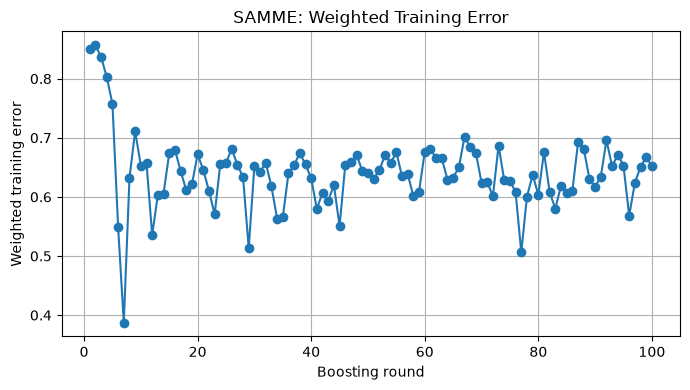

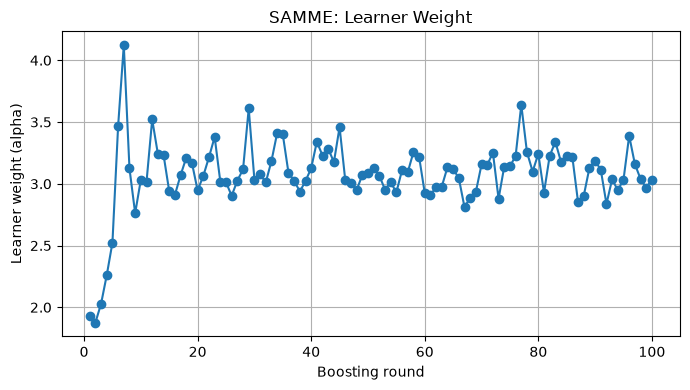

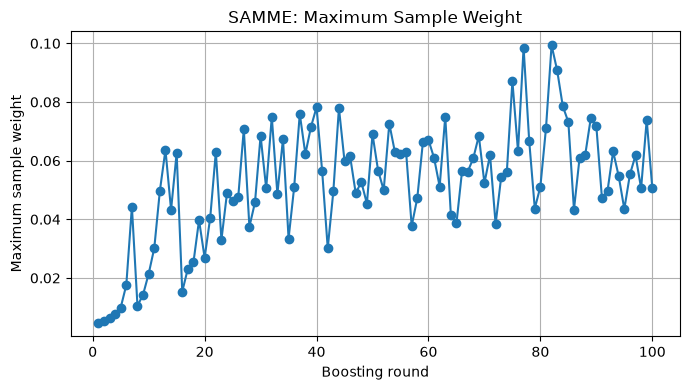

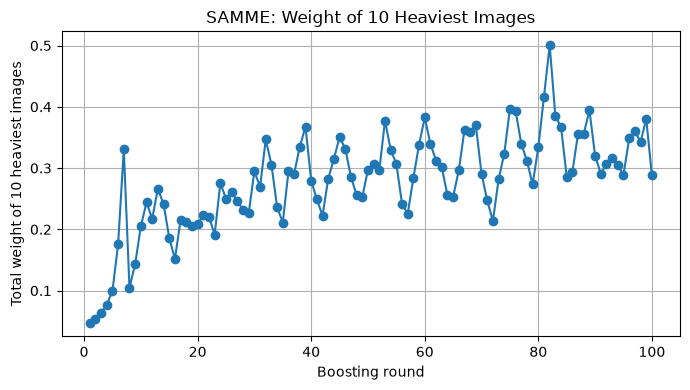

In [21]:


import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Step 1: Set experiment values
depth_values = [1, 2, 3, 4]
round_values = [10, 25, 50, 100]

K = len(np.unique(y_train))
n = len(y_train)
random_error = 1 - 1 / K

results = []
saved_models = {}


# Step 2: Function to train SAMME
def train_samme(depth, rounds):
    # Initially, all training images have equal weight
    w = np.ones(n) / n

    learners = []
    alphas = []

    weighted_errors = []
    alpha_history = []
    max_weight_history = []
    top10_weight_history = []

    for t in range(rounds):
        # Train one weak learner
        learner = DecisionTreeClassifier(
            max_depth=depth,
            random_state=seed + t
        )

        learner.fit(X_train, y_train, sample_weight=w)
        pred = learner.predict(X_train)

        # Calculate weighted error
        incorrect = (pred != y_train)
        error = np.sum(w * incorrect)

        # Reject a learner that is not better than random
        if error >= random_error:
            break

        # Avoid division by zero for a perfect learner
        safe_error = max(error, 1e-12)

        # SAMME learner weight
        alpha = np.log((1 - safe_error) / safe_error) + np.log(K - 1)

        # Save learner and round statistics
        learners.append(learner)
        alphas.append(alpha)

        weighted_errors.append(error)
        alpha_history.append(alpha)

        # Update weights: misclassified samples get more weight
        w = w * np.exp(alpha * incorrect)
        w = w / np.sum(w)

        max_weight_history.append(np.max(w))

        # Sum of the 10 largest sample weights
        top10_weight_history.append(
            np.sum(np.sort(w)[-10:])
        )

        # Stop if the learner classified every training image correctly
        if error == 0:
            break

    # Predict validation labels using weighted votes
    scores = np.zeros((len(X_val), K))

    for learner, alpha in zip(learners, alphas):
        pred_val = learner.predict(X_val)

        for class_id in range(K):
            scores[:, class_id] += alpha * (pred_val == class_id)

    if len(learners) > 0:
        val_pred = np.argmax(scores, axis=1)
    else:
        val_pred = np.zeros(len(X_val), dtype=int)

    val_accuracy = accuracy_score(y_val, val_pred)

    history = {
        "weighted_errors": weighted_errors,
        "alphas": alpha_history,
        "max_weights": max_weight_history,
        "top10_weights": top10_weight_history
    }

    return learners, alphas, val_accuracy, history


# Step 3: Try all 16 configurations
for depth in depth_values:
    for rounds in round_values:
        learners, alphas, val_acc, history = train_samme(
            depth, rounds
        )

        results.append({
            "depth": depth,
            "rounds": rounds,
            "validation_accuracy": val_acc,
            "actual_rounds": len(learners)
        })

        saved_models[(depth, rounds)] = (learners, alphas, history)

        print(
            f"Depth={depth}, Requested rounds={rounds}, "
            f"Actual rounds={len(learners)}, "
            f"Validation accuracy={val_acc:.4f}"
        )


# Step 4: Select using validation accuracy only
best_result = max(
    results,
    key=lambda item: item["validation_accuracy"]
)

best_depth_q2 = best_result["depth"]
best_rounds_q2 = best_result["rounds"]

best_learners, best_alphas, best_history = saved_models[
    (best_depth_q2, best_rounds_q2)
]

print("\nSelected depth:", best_depth_q2)
print("Selected rounds:", best_rounds_q2)
print(
    "Best validation accuracy:",
    best_result["validation_accuracy"]
)
print("Number of accepted learners:", len(best_learners))


# Step 5: Plot the four required graphs
rounds_axis = np.arange(1, len(best_learners) + 1)

plt.figure(figsize=(7, 4))
plt.plot(rounds_axis, best_history["weighted_errors"], marker="o")
plt.xlabel("Boosting round")
plt.ylabel("Weighted training error")
plt.title("SAMME: Weighted Training Error")
plt.grid(True)
plt.tight_layout()
plt.savefig("samme_weighted_error.png", dpi=300)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(rounds_axis, best_history["alphas"], marker="o")
plt.xlabel("Boosting round")
plt.ylabel("Learner weight (alpha)")
plt.title("SAMME: Learner Weight")
plt.grid(True)
plt.tight_layout()
plt.savefig("samme_learner_weight.png", dpi=300)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(rounds_axis, best_history["max_weights"], marker="o")
plt.xlabel("Boosting round")
plt.ylabel("Maximum sample weight")
plt.title("SAMME: Maximum Sample Weight")
plt.grid(True)
plt.tight_layout()
plt.savefig("samme_max_sample_weight.png", dpi=300)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(rounds_axis, best_history["top10_weights"], marker="o")
plt.xlabel("Boosting round")
plt.ylabel("Total weight of 10 heaviest images")
plt.title("SAMME: Weight of 10 Heaviest Images")
plt.grid(True)
plt.tight_layout()
plt.savefig("samme_top10_weight.png", dpi=300)
plt.show()


Question Number 2(C)


BAGGING RESULTS
B=25 | Train=1.0000 | Validation=0.8625 | Clean Test=0.7500 | Time=34.19 seconds
B=50 | Train=1.0000 | Validation=0.8875 | Clean Test=0.8250 | Time=68.25 seconds
B=100 | Train=1.0000 | Validation=0.9125 | Clean Test=0.8500 | Time=134.63 seconds

BOOSTING RESULTS
B=25 | Train=0.4458 | Validation=0.2250 | Clean Test=0.2125 | Time=9.48 seconds
B=50 | Train=0.9917 | Validation=0.4375 | Clean Test=0.4250 | Time=19.03 seconds
B=100 | Train=1.0000 | Validation=0.4625 | Clean Test=0.4000 | Time=38.75 seconds

HIGHEST-WEIGHT TRAINING IMAGE
Training sample position: 4
True identity: 0
Final sample weight: 0.05061678137023933

Prediction history for this image:
Round 1: Predicted=0, True=0, Correct=True, Weight after update=0.000694
Round 2: Predicted=1, True=0, Correct=False, Weight after update=0.000790
Round 3: Predicted=2, True=0, Correct=False, Weight after update=0.000921
Round 4: Predicted=3, True=0, Correct=False, Weight after update=0.001119
Round 5: Predicted=4, True=0,

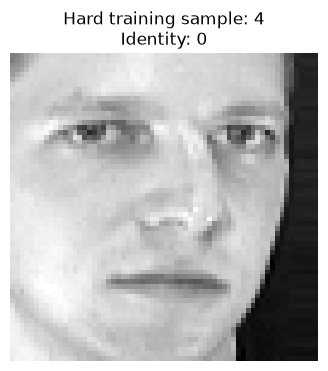

In [ ]:

# Compare Bagging and SAMME Boosting

import time

learner_counts = [25, 50, 100]
n = len(X_train)
K = len(np.unique(y_train))


# Helper: combine predictions using majority vote
def majority_vote(trees, X_data):
    predictions = np.array([
        tree.predict(X_data) for tree in trees
    ])

    final_predictions = []

    for j in range(len(X_data)):
        votes = np.bincount(predictions[:, j], minlength=K)
        final_predictions.append(np.argmax(votes))

    return np.array(final_predictions)


# Helper: combine predictions using SAMME weighted votes
def samme_predict(trees, alphas, X_data):
    scores = np.zeros((len(X_data), K))

    for tree, alpha in zip(trees, alphas):
        pred = tree.predict(X_data)

        for class_id in range(K):
            scores[:, class_id] += alpha * (pred == class_id)

    return np.argmax(scores, axis=1)



bagging_trees = []
bagging_times = []
bagging_rng = np.random.default_rng(seed)

start = time.perf_counter()

for i in range(100):
    sample_idx = bagging_rng.choice(
        n, size=n, replace=True
    )

    tree = DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_leaf=best_leaf,
        random_state=seed + i
    )

    tree.fit(X_train[sample_idx], y_train[sample_idx])
    bagging_trees.append(tree)

    bagging_times.append(time.perf_counter() - start)


boost_trees = []
boost_alphas = []

w = np.ones(n) / n
random_error = 1 - 1 / K

boosting_times = []
boosting_weight_history = []
boosting_prediction_history = []

start = time.perf_counter()

for t in range(100):
    tree = DecisionTreeClassifier(
        max_depth=best_depth_q2,
        random_state=seed + t
    )

    tree.fit(X_train, y_train, sample_weight=w)
    pred = tree.predict(X_train)

    incorrect = (pred != y_train)
    error = np.sum(w * incorrect)

    # Reject a weak learner that is not better than random
    if error >= random_error:
        print("Boosting stopped at round", t + 1,
              "because the learner was not better than random.")
        break

    safe_error = max(error, 1e-12)

    alpha = (
        np.log((1 - safe_error) / safe_error)
        + np.log(K - 1)
    )

    boost_trees.append(tree)
    boost_alphas.append(alpha)

    # Update and normalize sample weights
    w = w * np.exp(alpha * incorrect)
    w = w / np.sum(w)

    # Save each round's sample weights and predictions
    boosting_weight_history.append(w.copy())
    boosting_prediction_history.append(pred.copy())

    boosting_times.append(time.perf_counter() - start)

    if error == 0:
        break


print("\nBAGGING RESULTS")

for B in learner_counts:
    trees = bagging_trees[:B]

    train_pred = majority_vote(trees, X_train)
    val_pred = majority_vote(trees, X_val)
    test_pred = majority_vote(trees, X_test)

    print(
        f"B={B} | "
        f"Train={accuracy_score(y_train, train_pred):.4f} | "
        f"Validation={accuracy_score(y_val, val_pred):.4f} | "
        f"Clean Test={accuracy_score(y_test, test_pred):.4f} | "
        f"Time={bagging_times[B-1]:.2f} seconds"
    )


print("\nBOOSTING RESULTS")

for B in learner_counts:
    if len(boost_trees) < B:
        print("B =", B, "not reached; accepted rounds =",
              len(boost_trees))
        continue

    trees = boost_trees[:B]
    alphas = boost_alphas[:B]

    train_pred = samme_predict(trees, alphas, X_train)
    val_pred = samme_predict(trees, alphas, X_val)
    test_pred = samme_predict(trees, alphas, X_test)

    print(
        f"B={B} | "
        f"Train={accuracy_score(y_train, train_pred):.4f} | "
        f"Validation={accuracy_score(y_val, val_pred):.4f} | "
        f"Clean Test={accuracy_score(y_test, test_pred):.4f} | "
        f"Time={boosting_times[B-1]:.2f} seconds"
    )



if len(boosting_weight_history) > 0:
    final_weights = boosting_weight_history[-1]
    hard_sample = np.argmax(final_weights)

    print("\nHIGHEST-WEIGHT TRAINING IMAGE")
    print("Training sample position:", hard_sample)
    print("True identity:", y_train[hard_sample])
    print("Final sample weight:", final_weights[hard_sample])

    print("\nPrediction history for this image:")

    for t in range(len(boost_trees)):
        predicted = boosting_prediction_history[t][hard_sample]
        weight = boosting_weight_history[t][hard_sample]

        print(
            f"Round {t+1}: "
            f"Predicted={predicted}, "
            f"True={y_train[hard_sample]}, "
            f"Correct={predicted == y_train[hard_sample]}, "
            f"Weight after update={weight:.6f}"
        )

    # Display the selected training face
    import matplotlib.pyplot as plt

    plt.figure(figsize=(4, 4))
    plt.imshow(
        X_train[hard_sample].reshape(64, 64),
        cmap="gray"
    )
    plt.title(
        f"Hard training sample: {hard_sample}\n"
        f"Identity: {y_train[hard_sample]}"
    )
    plt.axis("off")
    plt.show()


In [22]:
# Recreate the 100 bagging trees required for Q2(d)

bagging_rng = np.random.default_rng(seed)
n_train = len(X_train)

bagging_trees = []

for i in range(100):
    sample_idx = bagging_rng.choice(
        n_train,
        size=n_train,
        replace=True
    )

    tree = DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_leaf=best_leaf,
        random_state=seed + i
    )

    tree.fit(X_train[sample_idx], y_train[sample_idx])
    bagging_trees.append(tree)

print("Bagging trees recreated:", len(bagging_trees))

Bagging trees recreated: 100


Question Number 2(D)

In [24]:

# Compare Tree, Bagging and Boosting

import numpy as np
from sklearn.metrics import accuracy_score

# Step 1: Freeze the selected models
single_tree = best_model

final_bagging_trees = bagging_trees[:100]

final_boost_trees, final_boost_alphas, _ = saved_models[
    (best_depth_q2, best_rounds_q2)
]


# Step 2: Create the masked test images
X_masked_test = X_test.reshape(-1, 64, 64).copy()
X_masked_test[:, 24:40, 24:40] = 0
X_masked_test = X_masked_test.reshape(-1, 4096)


# Step 3: Make predictions and calculate confidence
def get_bagging_results(trees, X_data):
    all_preds = np.array([
        tree.predict(X_data) for tree in trees
    ])

    predictions = []
    confidence = []
    vote_counts = []

    for j in range(len(X_data)):
        counts = np.bincount(all_preds[:, j], minlength=40)
        predictions.append(np.argmax(counts))
        confidence.append(np.max(counts) / len(trees))
        vote_counts.append(counts)

    return (
        np.array(predictions),
        np.array(confidence),
        np.array(vote_counts),
        all_preds
    )


def get_boosting_results(trees, alphas, X_data):
    scores = np.zeros((len(X_data), 40))
    all_preds = []

    for tree, alpha in zip(trees, alphas):
        pred = tree.predict(X_data)
        all_preds.append(pred)

        for class_id in range(40):
            scores[:, class_id] += alpha * (pred == class_id)

    all_preds = np.array(all_preds)
    predictions = np.argmax(scores, axis=1)

    confidence = np.max(scores, axis=1) / np.sum(alphas)

    return predictions, confidence, scores, all_preds


# Step 4: Evaluate all three models
def evaluate_all(X_data, set_name):
    tree_pred = single_tree.predict(X_data)
    tree_conf = np.max(single_tree.predict_proba(X_data), axis=1)

    bag_pred, bag_conf, bag_votes, bag_all = get_bagging_results(
        final_bagging_trees, X_data
    )

    boost_pred, boost_conf, boost_scores, boost_all = (
        get_boosting_results(
            final_boost_trees, final_boost_alphas, X_data
        )
    )

    print("\n", set_name)

    print(
        "Single Tree | Accuracy:",
        round(accuracy_score(y_test, tree_pred), 4),
        "| Mean confidence:",
        round(np.mean(tree_conf), 4)
    )

    print(
        "Bagging | Accuracy:",
        round(accuracy_score(y_test, bag_pred), 4),
        "| Mean winning vote:",
        round(np.mean(bag_conf), 4)
    )

    print(
        "Boosting | Accuracy:",
        round(accuracy_score(y_test, boost_pred), 4),
        "| Mean normalized vote:",
        round(np.mean(boost_conf), 4)
    )

    return {
        "tree_pred": tree_pred,
        "tree_conf": tree_conf,
        "bag_pred": bag_pred,
        "bag_conf": bag_conf,
        "bag_votes": bag_votes,
        "bag_all": bag_all,
        "boost_pred": boost_pred,
        "boost_conf": boost_conf,
        "boost_scores": boost_scores,
        "boost_all": boost_all
    }


clean_results = evaluate_all(X_test, "CLEAN TEST SET")

masked_results = evaluate_all(
    X_masked_test, "MASKED TEST SET"
)


# Step 5: Find a face where Bagging and Boosting
# respond differently to masking
chosen_face = None

for i in range(len(y_test)):
    bag_changed = (
        clean_results["bag_pred"][i]
        != masked_results["bag_pred"][i]
    )

    boost_changed = (
        clean_results["boost_pred"][i]
        != masked_results["boost_pred"][i]
    )

    if bag_changed != boost_changed:
        chosen_face = i
        break


# Step 6: Print the selected face's results
if chosen_face is not None:
    i = chosen_face

    print("\nFACE WITH DIFFERENT RESPONSE TO MASKING")
    print("Test face index:", i)
    print("True identity:", y_test[i])

    print("\nBagging clean prediction:",
          clean_results["bag_pred"][i])
    print("Bagging masked prediction:",
          masked_results["bag_pred"][i])

    print("Bagging clean winning votes:",
          clean_results["bag_votes"][i].max(), "out of 100")
    print("Bagging masked winning votes:",
          masked_results["bag_votes"][i].max(), "out of 100")

    print("\nBoosting clean prediction:",
          clean_results["boost_pred"][i])
    print("Boosting masked prediction:",
          masked_results["boost_pred"][i])

    print("Boosting clean normalized vote:",
          round(clean_results["boost_conf"][i], 4))
    print("Boosting masked normalized vote:",
          round(masked_results["boost_conf"][i], 4))

    # Inspect tree disagreement for this face
    print("\nBagging tree predictions on the clean face:")
    print(np.bincount(
        clean_results["bag_all"][:, i], minlength=40
    ))

    print("Bagging tree predictions on the masked face:")
    print(np.bincount(
        masked_results["bag_all"][:, i], minlength=40
    ))

    # Show training samples with the largest final boosting weights
    _, _, boost_history = saved_models[
        (best_depth_q2, best_rounds_q2)
    ]

    # Reconstruct final training weights from the last
   # Print highest-weight training samples only if weights exist

if "boosting_weight_history" in globals() and len(boosting_weight_history) > 0:
    final_weights = boosting_weight_history[-1]
    hardest = np.argsort(final_weights)[-5:][::-1]

    print("\nFive highest-weight training samples:")
    for sample in hardest:
        print(
            "Training position:", sample,
            "| True identity:", y_train[sample],
            "| Final weight:", round(final_weights[sample], 6)
        )
else:
    print("\nBoosting weight history is unavailable.")
    print("Skipping the optional training-weight analysis.")



 CLEAN TEST SET
Single Tree | Accuracy: 0.5125 | Mean confidence: 1.0
Bagging | Accuracy: 0.85 | Mean winning vote: 0.3852
Boosting | Accuracy: 0.4 | Mean normalized vote: 0.1219

 MASKED TEST SET
Single Tree | Accuracy: 0.3375 | Mean confidence: 1.0
Bagging | Accuracy: 0.725 | Mean winning vote: 0.269
Boosting | Accuracy: 0.375 | Mean normalized vote: 0.1219

FACE WITH DIFFERENT RESPONSE TO MASKING
Test face index: 0
True identity: 0

Bagging clean prediction: 0
Bagging masked prediction: 0
Bagging clean winning votes: 34 out of 100
Bagging masked winning votes: 19 out of 100

Boosting clean prediction: 0
Boosting masked prediction: 3
Boosting clean normalized vote: 0.1143
Boosting masked normalized vote: 0.1077

Bagging tree predictions on the clean face:
[34  0  1  3  1  1  1 20  0  9  2  0  0  1  2  9  2  3  0  0  0  0  0  0
  2  2  2  2  0  0  0  0  0  0  1  1  0  1  0  0]
Bagging tree predictions on the masked face:
[19  1  0  4  0  1  0 16  0  4  2  0  2  4  4  5  0  1  0  0  5

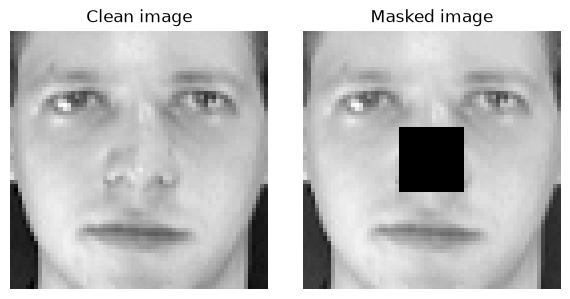

True identity: 0
Bagging: clean = 0, masked = 0
Boosting: clean = 0, masked = 3
Figure saved: figures/clean_vs_masked_example.png


In [25]:
import os
import matplotlib.pyplot as plt

idx = 0
os.makedirs("figures", exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))

axes[0].imshow(X_test[idx].reshape(64, 64), cmap="gray")
axes[0].set_title("Clean image")

axes[1].imshow(X_masked_test[idx].reshape(64, 64), cmap="gray")
axes[1].set_title("Masked image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    "figures/clean_vs_masked_example.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("True identity:", y_test[idx])
print("Bagging: clean = 0, masked = 0")
print("Boosting: clean = 0, masked = 3")
print("Figure saved: figures/clean_vs_masked_example.png")

Question Number 3(A)

In [27]:

# Q3(a) faster version: parallelize the 30 repetitions

from joblib import Parallel, delayed
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

K = 40
R = 30
N = len(y_test)

y_one_hot = np.eye(K)[y_test]

# Reproducible resampled training sets
q3_rng = np.random.default_rng(seed + 300)
identity_positions = {
    c: np.where(y_train == c)[0] for c in range(K)
}

resampled_sets = []
for r in range(R):
    positions = []
    for c in range(K):
        positions.extend(
            q3_rng.choice(identity_positions[c], size=6, replace=True)
        )
    positions = np.array(positions)
    resampled_sets.append((X_train[positions], y_train[positions]))


def run_one_repetition(r):
    Xr, yr = resampled_sets[r]
    rng = np.random.default_rng(seed + 10000 + r)

    # Single tree
    tree = DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_leaf=best_leaf,
        random_state=seed + r
    )
    tree.fit(Xr, yr)
    tp = tree.predict(X_test)
    tv = tree.predict_proba(X_test)

    # Bagging: 100 trees
    bag_votes = np.zeros((N, K))
    for b in range(100):
        ix = rng.choice(len(yr), size=len(yr), replace=True)
        model = DecisionTreeClassifier(
            max_depth=best_depth,
            min_samples_leaf=best_leaf,
            random_state=seed + r * 1000 + b
        )
        model.fit(Xr[ix], yr[ix])
        pred = model.predict(X_test)
        bag_votes[np.arange(N), pred] += 0.01

    bp = np.argmax(bag_votes, axis=1)

    # SAMME boosting: selected depth and 100 rounds
    weights = np.ones(len(yr)) / len(yr)
    boost_models = []
    boost_alphas = []

    for t in range(best_rounds_q2):
        model = DecisionTreeClassifier(
            max_depth=best_depth_q2,
            random_state=seed + 20000 + r + t
        )
        model.fit(Xr, yr, sample_weight=weights)
        pred_train = model.predict(Xr)
        wrong = pred_train != yr
        err = np.sum(weights * wrong)

        if err >= 1 - 1/K:
            break

        err = max(err, 1e-12)
        alpha = np.log((1-err)/err) + np.log(K-1)
        boost_models.append(model)
        boost_alphas.append(alpha)

        weights *= np.exp(alpha * wrong)
        weights /= weights.sum()

        if err <= 1e-12:
            break

    scores = np.zeros((N, K))
    for model, alpha in zip(boost_models, boost_alphas):
        pred = model.predict(X_test)
        scores[np.arange(N), pred] += alpha

    if sum(boost_alphas) > 0:
        boost_votes = scores / sum(boost_alphas)
    else:
        boost_votes = np.ones((N, K)) / K

    # Return probabilities/vote vectors and accuracy
    return (
        tv,
        bag_votes,
        boost_votes,
        accuracy_score(y_test, tp),
        accuracy_score(y_test, bp),
        accuracy_score(y_test, np.argmax(boost_votes, axis=1))
    )


# Two workers to limit memory use
results_q3 = Parallel(n_jobs=2, verbose=10)(
    delayed(run_one_repetition)(r) for r in range(R)
)

tree_vectors = np.array([v[0] for v in results_q3])
bag_vectors = np.array([v[1] for v in results_q3])
boost_vectors = np.array([v[2] for v in results_q3])

tree_accuracies = np.array([v[3] for v in results_q3])
bag_accuracies = np.array([v[4] for v in results_q3])
boost_accuracies = np.array([v[5] for v in results_q3])


def measure_bias_variance(vectors):
    mean_vectors = vectors.mean(axis=0)

    bias2 = np.mean(
        np.sum((mean_vectors - y_one_hot)**2, axis=1)
    )
    variance = np.mean(
        np.sum((vectors - mean_vectors[None, :, :])**2, axis=2)
    )
    return bias2, variance


print("\n========== Q3(a) RESULTS ==========")

for name, vectors, accuracies in [
    ("Single Tree", tree_vectors, tree_accuracies),
    ("Bagging", bag_vectors, bag_accuracies),
    ("Boosting", boost_vectors, boost_accuracies)
]:
    bias2, variance = measure_bias_variance(vectors)
    print(f"\n{name}")
    print(f"Bias^2: {bias2:.6f}")
    print(f"Variance: {variance:.6f}")
    print(f"Mean test accuracy: {accuracies.mean():.4f}")
    print(f"Std test accuracy: {accuracies.std():.4f}")


[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:  4.2min
[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:  7.5min
[Parallel(n_jobs=2)]: Done   9 tasks      | elapsed: 27.9min
[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed: 35.2min
[Parallel(n_jobs=2)]: Done  21 tasks      | elapsed: 48.4min
[Parallel(n_jobs=2)]: Done  30 out of  30 | elapsed: 72.0min finished



========== Q3(a) RESULTS ==========

Single Tree
Bias^2: 0.397778
Variance: 0.645556
Mean test accuracy: 0.4783
Std test accuracy: 0.0550

Bagging
Bias^2: 0.513596
Variance: 0.023400
Mean test accuracy: 0.7546
Std test accuracy: 0.0339

Boosting
Bias^2: 0.880129
Variance: 0.016738
Mean test accuracy: 0.3500
Std test accuracy: 0.0795


Question Number 3(B)

In [13]:

# Recreate the 30 resampled training datasets for Q3(b)
# Six training faces per identity, sampled with replacement

R = 30
resample_rng = np.random.default_rng(seed + 300)
resampled_sets = []

for rep in range(R):
    selected_positions = []

    for identity in range(40):
        # Positions of this identity among the original training data
        positions = np.where(y_train == identity)[0]

        # Select 6 positions with replacement
        chosen = resample_rng.choice(
            positions, size=6, replace=True
        )
        selected_positions.extend(chosen)

    selected_positions = np.array(selected_positions)

    Xr = X_train[selected_positions]
    yr = y_train[selected_positions]

    resampled_sets.append((Xr, yr))

print("Number of resampled datasets:", len(resampled_sets))
print("Shape of one resampled dataset:", resampled_sets[0][0].shape)
print("Selected tree depth:", best_depth)
print("Selected leaf setting:", best_leaf)


Number of resampled datasets: 30
Shape of one resampled dataset: (240, 4096)
Selected tree depth: None
Selected leaf setting: 1


In [14]:

from joblib import Parallel, delayed
from sklearn.tree import DecisionTreeClassifier
import numpy as np

# Three depth settings
depth_settings = [
    ("Shallow (2)", 2),
    ("Selected (None)", None),
    ("Deep (32)", 32)
]

N = len(y_test)
K = 40
R = len(resampled_sets)

# One-hot true labels
y_one_hot = np.eye(K)[y_test]


def run_depth_experiment(rep, depth_index, depth):
    # Reuse the existing resampled training dataset
    Xr, yr = resampled_sets[rep]

    # Reproducible random generator for this experiment
    rng = np.random.default_rng(
        seed + 10000 * (rep + 1) + 100 * (depth_index + 1)
    )

    # 1. Fit one decision tree
    single_tree = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=best_leaf,
        random_state=seed + rep + 100 * (depth_index + 1)
    )
    single_tree.fit(Xr, yr)

    # Convert probabilities into a consistent 40-class vector
    single_pred = single_tree.predict(X_test)
    single_prob = np.zeros((N, K))
    single_prob[:, single_tree.classes_.astype(int)] = (
        single_tree.predict_proba(X_test)
    )

    single_accuracy = accuracy_score(y_test, single_pred)
    actual_single_depth = single_tree.tree_.max_depth

    # 2. Train a 100-tree bagging ensemble
    B = 100
    bag_votes = np.zeros((N, K))
    bag_tree_depths = []

    for b in range(B):
        # Bootstrap sample from this resampled training set
        sample_idx = rng.choice(len(yr), size=len(yr), replace=True)

        tree = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=best_leaf,
            random_state=seed + rep * 10000
                        + depth_index * 1000 + b
        )

        tree.fit(Xr[sample_idx], yr[sample_idx])

        predictions = tree.predict(X_test)
        np.add.at(
            bag_votes,
            (np.arange(N), predictions.astype(int)),
            1
        )

        bag_tree_depths.append(tree.tree_.max_depth)

    # Convert votes into normalized class vectors
    bag_vectors = bag_votes / B
    bag_predictions = bag_votes.argmax(axis=1)
    bag_accuracy = accuracy_score(y_test, bag_predictions)

    return (
        single_prob,
        bag_vectors,
        single_accuracy,
        bag_accuracy,
        actual_single_depth,
        np.mean(bag_tree_depths)
    )


# Run 30 repetitions for each of the 3 depths.
# This is computationally expensive; keep the notebook running.
all_results = {}

for depth_index, (depth_name, depth) in enumerate(depth_settings):
    print(f"\nStarting: {depth_name}")

    results = Parallel(n_jobs=2, verbose=10)(
        delayed(run_depth_experiment)(rep, depth_index, depth)
        for rep in range(R)
    )

    all_results[depth_name] = results
    print(f"Finished: {depth_name}")


# 3. Calculate bias squared, variance and accuracy statistics
q3b_summary = {}

for depth_name, results in all_results.items():
    single_vectors = np.array([r[0] for r in results])
    bag_vectors = np.array([r[1] for r in results])

    single_acc = np.array([r[2] for r in results])
    bag_acc = np.array([r[3] for r in results])

    # Mean prediction vector across the 30 fitted models
    single_mean = single_vectors.mean(axis=0)
    bag_mean = bag_vectors.mean(axis=0)

    # Bias squared: average squared distance from the true one-hot label
    single_bias2 = np.mean(np.sum(
        (single_mean - y_one_hot) ** 2, axis=1
    ))
    bag_bias2 = np.mean(np.sum(
        (bag_mean - y_one_hot) ** 2, axis=1
    ))

    # Variance: average squared distance from the mean prediction
    single_variance = np.mean(np.sum(
        (single_vectors - single_mean[None, :, :]) ** 2,
        axis=2
    ))
    bag_variance = np.mean(np.sum(
        (bag_vectors - bag_mean[None, :, :]) ** 2,
        axis=2
    ))

    # Amount of variance removed by bagging
    variance_removed = single_variance - bag_variance
    variance_removed_pct = (
        100 * variance_removed / single_variance
        if single_variance > 0 else 0
    )

    q3b_summary[depth_name] = {
        "single_bias2": single_bias2,
        "single_variance": single_variance,
        "bag_bias2": bag_bias2,
        "bag_variance": bag_variance,
        "variance_removed": variance_removed,
        "variance_removed_pct": variance_removed_pct,
        "single_mean_accuracy": single_acc.mean(),
        "single_std_accuracy": single_acc.std(),
        "bag_mean_accuracy": bag_acc.mean(),
        "bag_std_accuracy": bag_acc.std(),
        "actual_single_depth": np.mean([r[4] for r in results]),
        "actual_bag_depth": np.mean([r[5] for r in results])
    }

    print(f"\n{depth_name}")
    print(f"Single tree Bias^2: {single_bias2:.6f}")
    print(f"Single tree Variance: {single_variance:.6f}")
    print(f"Bagging Bias^2: {bag_bias2:.6f}")
    print(f"Bagging Variance: {bag_variance:.6f}")
    print(f"Variance removed: {variance_removed:.6f}")
    print(f"Variance removed (%): {variance_removed_pct:.2f}%")
    print(f"Single tree accuracy: {single_acc.mean():.4f}"
          f" +/- {single_acc.std():.4f}")
    print(f"Bagging accuracy: {bag_acc.mean():.4f}"
          f" +/- {bag_acc.std():.4f}")
    print(f"Average actual single-tree depth: "
          f"{np.mean([r[4] for r in results]):.2f}")
    print(f"Average actual bagging-tree depth: "
          f"{np.mean([r[5] for r in results]):.2f}")



Starting: Shallow (2)


[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:   41.5s
[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:  1.2min
[Parallel(n_jobs=2)]: Done   9 tasks      | elapsed:  2.8min
[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed:  3.8min
[Parallel(n_jobs=2)]: Done  21 tasks      | elapsed:  5.9min
[Parallel(n_jobs=2)]: Done  30 out of  30 | elapsed:  7.9min finished
[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.


Finished: Shallow (2)

Starting: Selected (None)


[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:  4.3min
[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:  9.1min
[Parallel(n_jobs=2)]: Done   9 tasks      | elapsed: 23.8min
[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed: 38.1min
[Parallel(n_jobs=2)]: Done  21 tasks      | elapsed: 54.7min
[Parallel(n_jobs=2)]: Done  30 out of  30 | elapsed: 252.3min finished
[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.


Finished: Selected (None)

Starting: Deep (32)


[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:  4.0min
[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:  7.7min
[Parallel(n_jobs=2)]: Done   9 tasks      | elapsed: 18.1min
[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed: 25.6min
[Parallel(n_jobs=2)]: Done  21 tasks      | elapsed: 42.3min
[Parallel(n_jobs=2)]: Done  30 out of  30 | elapsed: 57.4min finished


Finished: Deep (32)

Shallow (2)
Single tree Bias^2: 0.916852
Single tree Variance: 0.037680
Bagging Bias^2: 0.929433
Bagging Variance: 0.011059
Variance removed: 0.026621
Variance removed (%): 70.65%
Single tree accuracy: 0.0600 +/- 0.0131
Bagging accuracy: 0.1608 +/- 0.0489
Average actual single-tree depth: 2.00
Average actual bagging-tree depth: 2.00

Selected (None)
Single tree Bias^2: 0.417556
Single tree Variance: 0.661611
Bagging Bias^2: 0.513445
Bagging Variance: 0.023138
Variance removed: 0.638474
Variance removed (%): 96.50%
Single tree accuracy: 0.4604 +/- 0.0292
Bagging accuracy: 0.7562 +/- 0.0326
Average actual single-tree depth: 34.57
Average actual bagging-tree depth: 37.56

Deep (32)
Single tree Bias^2: 0.425496
Single tree Variance: 0.563642
Bagging Bias^2: 0.525856
Bagging Variance: 0.022151
Variance removed: 0.541492
Variance removed (%): 96.07%
Single tree accuracy: 0.4579 +/- 0.0449
Bagging accuracy: 0.7483 +/- 0.0382
Average actual single-tree depth: 32.00
Average

In [15]:

for depth_name, values in q3b_summary.items():
    print("\n", depth_name)
    print("Single tree Bias^2:", round(values["single_bias2"], 6))
    print("Single tree Variance:", round(values["single_variance"], 6))
    print("Bagging Bias^2:", round(values["bag_bias2"], 6))
    print("Bagging Variance:", round(values["bag_variance"], 6))
    print("Variance removed (%):", round(values["variance_removed_pct"], 2))
    print("Single tree accuracy:", round(values["single_mean_accuracy"], 4))
    print("Bagging accuracy:", round(values["bag_mean_accuracy"], 4))



 Shallow (2)
Single tree Bias^2: 0.916852
Single tree Variance: 0.03768
Bagging Bias^2: 0.929433
Bagging Variance: 0.011059
Variance removed (%): 70.65
Single tree accuracy: 0.06
Bagging accuracy: 0.1608

 Selected (None)
Single tree Bias^2: 0.417556
Single tree Variance: 0.661611
Bagging Bias^2: 0.513445
Bagging Variance: 0.023138
Variance removed (%): 96.5
Single tree accuracy: 0.4604
Bagging accuracy: 0.7562

 Deep (32)
Single tree Bias^2: 0.425496
Single tree Variance: 0.563642
Bagging Bias^2: 0.525856
Bagging Variance: 0.022151
Variance removed (%): 96.07
Single tree accuracy: 0.4579
Bagging accuracy: 0.7483


### Q3(c) Is the deepest tree necessarily the depth at which bagging gives the largest improvement in test accuracy?

No, the deepest tree is not necessarily the depth at which bagging gives the largest improvement in test accuracy. Our experimental results demonstrate this.

| Tree depth | Single-tree accuracy | Bagging accuracy | Improvement |
|---|---:|---:|---:|
| Shallow (2) | 0.0600 | 0.1608 | +0.1008 |
| Selected (unrestricted) | 0.4604 | 0.7562 | +0.2958 |
| Deep (32) | 0.4579 | 0.7483 | +0.2904 |

The unrestricted selected tree gives the largest absolute improvement in test accuracy (0.2958), slightly higher than the depth-32 tree (0.2904). Therefore, the deepest tree does not provide the largest improvement in our experiment.

The measured bias and variance results help explain this observation. The selected tree has a single-tree variance of 0.661611, which bagging reduces to 0.023138, a reduction of 96.50%. For the depth-32 tree, variance decreases from 0.563642 to 0.022151, a reduction of 96.07%. Thus, the selected tree has slightly more variance available to reduce, and its accuracy improvement is marginally larger. The shallow tree has much lower variance (0.037680), but its bias² is very high (0.916852), indicating substantial underfitting. Bagging reduces its variance by 70.65%, yet its test accuracy remains low.

Leaf occupancy and disagreement results provide further evidence. In Q1(a), the selected unrestricted tree had 44 leaves, an average of 5.45 training samples per leaf, and 9.09% single-sample leaves. These small and unevenly occupied leaves indicate that some predictions depend on relatively few training examples. In Q1(c), the bagged trees' validation disagreement was approximately 0.77–0.78 for ensemble sizes of 10–200, showing that individual trees often disagreed. Such disagreement allows majority voting to reduce the effect of unstable individual predictions.

Overall, the depth-32 tree is not guaranteed to benefit most from bagging. In our measured results, the unrestricted selected tree achieved the largest test-accuracy improvement, while both unrestricted and depth-32 trees benefited greatly from variance reduction. The observed leaf occupancy and high ensemble disagreement support this conclusion.


### Q3(d) Final comparison of the selected models

The following table compares the selected single tree, bagging, and boosting models using their clean test accuracy, masked test accuracy, and measured bias–variance values.

| Model | Clean test accuracy | Masked test accuracy | Bias² | Variance |
|---|---:|---:|---:|---:|
| Selected single tree | 0.5125 | 0.3375 | 0.397778 | 0.645556 |
| Bagging (100 trees) | 0.8500 | 0.7250 | 0.513596 | 0.023400 |
| SAMME Boosting (depth 4, 100 rounds) | 0.4000 | 0.3750 | 0.880129 | 0.016738 |

**Note:** Bias² and variance are the measured values from Q3(a), computed using the 30 resampled training sets. The clean and masked accuracies are from the selected models evaluated in Q1(d) and Q2(d).

#### Discussion

**1. Which model is most stable?**

Boosting has the lowest measured variance (0.016738), followed by bagging (0.023400). Therefore, according to this particular bias–variance measurement, boosting is the most stable across resampled training sets. Bagging also has low variance and substantially better test accuracy. Stability here refers to prediction-vector variability across resampled training sets, not necessarily robustness to missing image regions.

**2. Which model is most sensitive to the missing region?**

Comparing clean and masked test accuracy:

- Single tree: \(0.5125-0.3375=0.1750\), a decrease of 17.50 percentage points.
- Bagging: \(0.8500-0.7250=0.1250\), a decrease of 12.50 percentage points.
- Boosting: \(0.4000-0.3750=0.0250\), a decrease of 2.50 percentage points.

The single tree is most sensitive to the masked region because it experiences the largest accuracy drop. Boosting has the smallest drop in this experiment, although its accuracy is already low on clean images. Thus, the smallest drop alone does not mean the best overall model.

**3. Does the model with the lowest variance necessarily have the best test accuracy?**

No. Boosting has the lowest variance (0.016738), but its clean test accuracy is only 0.4000. Bagging has a slightly higher variance (0.023400) but achieves the highest clean test accuracy (0.8500) and masked test accuracy (0.7250).

Boosting's measured bias² is also much higher (0.880129) than that of the single tree (0.397778) and bagging (0.513596). Its predictions are comparatively consistent across resampled datasets, but they are often incorrect. This demonstrates that low variance alone does not guarantee high accuracy.

#### Final conclusion

Among the three selected models, bagging provides the best overall performance: it achieves the highest clean and masked test accuracies while substantially reducing variance compared with a single tree. The single tree is most sensitive to the missing region, while boosting has the lowest measured variance and the smallest observed accuracy drop. However, boosting's low variance comes with high bias and poor test accuracy. Therefore, stability, robustness to masking, and predictive accuracy must be evaluated separately.
